# **PRAKTIKUM 2**

### **Klasifikasi Multi Class pada Dataset Iris**

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import tensorflow as tf
import random

# Load dataset
data = pd.read_csv('../Data/jakarta_house.csv')
data['land_area'] = data['land_area'].fillna(data['land_area'].mean())
data['building_area'] = data['building_area'].fillna(data['building_area'].mean())

features = ['price', 'bed_rooms', 'bath_rooms', 'carport', 'land_area', 'building_area']
X = data[features].values
y = data[['city']].values

# Standardisasi
scaler = StandardScaler()
X = scaler.fit_transform(X)

# One-hot encoding
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Menghapus sesi/memori model sebelumnya agar hitungan random diulang dari titik 0
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# Bangun model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(y.shape[1], activation='softmax')
])

# Kompilasi
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Latih model
model.fit(X_train, y_train, epochs=50, batch_size=32)

# Evaluasi
print("\n")
print("Evaluasi:")
loss, acc = model.evaluate(X_test, y_test)
print(f"Akurasi: {acc}")

Epoch 1/50


  1/250 ━━━━━━━━━━━━━━━━━━━━ 5:10 1s/step - accuracy: 0.2188 - loss: 1.6691

 26/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1947 - loss: 1.7123 

 53/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2294 - loss: 1.6907

 73/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2449 - loss: 1.6671

 95/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2589 - loss: 1.6526

... (617 outputs left out)

47/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4767 - loss: 1.2540

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4800 - loss: 1.2614

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4800 - loss: 1.2614


Akurasi: 0.47999998927116394


# **PRAKTIKUM 3**

### **Model Regresi untuk Prediksi Harga Rumah**

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Load dataset
data = pd.read_csv('../Data/jakarta_house.csv')
data['building_area'] = data['building_area'].fillna(data['building_area'].mean())

X = data[['building_area']]
y = data[['price']]

# Menggunakan scaler terpisah agar bisa dikembalikan ke harga asli
scaler_x = StandardScaler()
scaler_y = StandardScaler()
X_scaled = scaler_x.fit_transform(X)
y_scaled = scaler_y.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)

# Menghapus sesi/memori model sebelumnya agar hitungan random diulang dari titik 0
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# Model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(1,)),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100, batch_size=64)

# Evaluasi
pred_scaled = model.predict(X_test)
pred_asli = scaler_y.inverse_transform(pred_scaled)

print("\n")
print("Evaluasi")
print("Prediksi (Skala Normalisasi):", pred_scaled)
print("Prediksi (Skala Harga Asli):", pred_asli)

Epoch 1/100


  1/125 ━━━━━━━━━━━━━━━━━━━━ 1:20 648ms/step - loss: 0.3140

 32/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6065    

 62/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6531

 87/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6110

117/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5823

... (686 outputs left out)

 1/63 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step

49/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step




Evaluasi
Prediksi (Skala Normalisasi): [[-0.00224638]
 [ 0.37722212]
 [ 0.6360282 ]
 ...
 [-0.19690892]
 [-0.37007707]
 [-0.37741467]]
Prediksi (Skala Harga Asli): [[9.9952640e+09]
 [1.7601401e+10]
 [2.2788956e+10]
 ...
 [6.0934118e+09]
 [2.6223974e+09]
 [2.4753213e+09]]


### **MLP Regresi Studi Kasus Boston Housing**

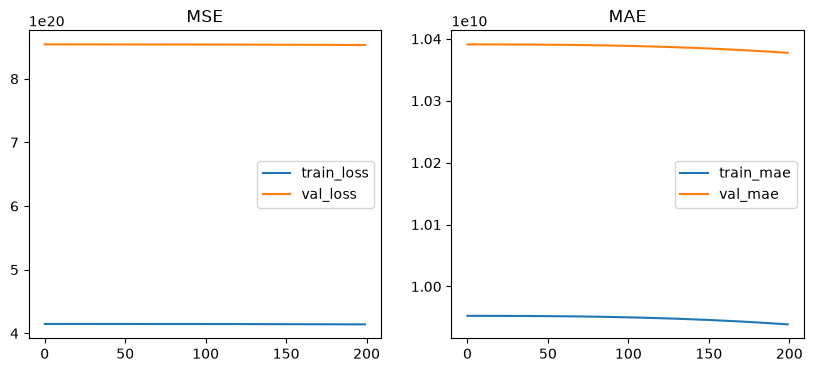

MSE: 8.530394014254534e+20
RMSE: 29206838264.787468
MAE: 10377379840.0


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

df = pd.read_csv('../Data/jakarta_house.csv')
df['land_area'] = df['land_area'].fillna(df['land_area'].mean())
df['building_area'] = df['building_area'].fillna(df['building_area'].mean())

# Memisahkan fitur (X) dan target (y)
features = ['bed_rooms', 'bath_rooms', 'carport', 'land_area', 'building_area']
X = df[features].values
y = df['price'].values.reshape(-1, 1)

# Preprocess
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Menghapus sesi/memori model sebelumnya agar hitungan random diulang dari titik 0
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# Model
model = Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1)
])
model.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

# Train Model
h = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=200, batch_size=64, verbose=0)

# 5. Plot
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(h.history['loss'],label='train_loss')
plt.plot(h.history['val_loss'], label='val_loss')
plt.legend()
plt.title('MSE')

plt.subplot(1,2,2)
plt.plot(h.history['mae'], label='train_mae')
plt.plot(h.history['val_mae'], label='val_mae')
plt.legend()
plt.title('MAE')
plt.show()

pred = model.predict(X_test, verbose=0)
print('MSE:', mean_squared_error(y_test, pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, pred)))
print('MAE:', mean_absolute_error(y_test, pred))